# NLP Lab Assignment 10

In [1]:
import gc
import os
import re
import random
import zipfile
from pathlib import Path

from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from gensim.models import KeyedVectors
from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)

pd.set_option("display.max_colwidth", None)

In [2]:
# Configurable dataset and embedding paths
DATA_DIR = Path("data")
TRAIN_PATH = DATA_DIR / "amazon-reviews" / "train.csv"
TEST_PATH = DATA_DIR / "amazon-reviews" / "test.csv"
ANALOGY_PATH = DATA_DIR / "questions-words.txt"

WORD2VEC_LOCAL_PATH = DATA_DIR / "embeddings" / "word2vec" / "word2vec-google-news-300.model"
GLOVE_TXT_PATH = DATA_DIR / "embeddings" / "glove" / "glove.6B.300d.txt"
GLOVE_KV_PATH = DATA_DIR / "embeddings" / "glove" / "glove.6B.300d.kv"
FASTTEXT_ZIP_PATH = DATA_DIR / "embeddings" / "fasttext" / "wiki-news-300d-1M-subword.vec.zip"
FASTTEXT_VEC_PATH = DATA_DIR / "embeddings" / "fasttext" / "wiki-news-300d-1M-subword.vec"
FASTTEXT_KV_PATH = DATA_DIR / "embeddings" / "fasttext" / "wiki-news-300d-1M-subword.kv"

def resolve_word2vec_path():
    if WORD2VEC_LOCAL_PATH.exists():
        return WORD2VEC_LOCAL_PATH
    try:
        model_path = hf_hub_download("fse/word2vec-google-news-300", "word2vec-google-news-300.model", local_files_only=True)
        hf_hub_download("fse/word2vec-google-news-300", "word2vec-google-news-300.model.vectors.npy", local_files_only=True)
        return Path(model_path)
    except Exception:
        model_path = hf_hub_download("fse/word2vec-google-news-300", "word2vec-google-news-300.model")
        hf_hub_download("fse/word2vec-google-news-300", "word2vec-google-news-300.model.vectors.npy")
        return Path(model_path)

WORD2VEC_PATH = resolve_word2vec_path()

def load_embeddings(name):
    if name == "Word2Vec":
        return KeyedVectors.load(str(WORD2VEC_PATH), mmap="r")
    if name == "GloVe":
        if GLOVE_KV_PATH.exists():
            return KeyedVectors.load(str(GLOVE_KV_PATH), mmap="r")
        kv = KeyedVectors.load_word2vec_format(str(GLOVE_TXT_PATH), binary=False, no_header=True)
        kv.save(str(GLOVE_KV_PATH))
        return kv
    if name == "FastText":
        if FASTTEXT_KV_PATH.exists():
            return KeyedVectors.load(str(FASTTEXT_KV_PATH), mmap="r")
        if not FASTTEXT_VEC_PATH.exists() and FASTTEXT_ZIP_PATH.exists():
            with zipfile.ZipFile(FASTTEXT_ZIP_PATH) as zf:
                zf.extractall(FASTTEXT_VEC_PATH.parent)
        kv = KeyedVectors.load_word2vec_format(str(FASTTEXT_VEC_PATH), binary=False)
        kv.save(str(FASTTEXT_KV_PATH))
        return kv
    raise ValueError(f"Unknown model: {name}")

file_status = [
    ("Amazon Train CSV", TRAIN_PATH),
    ("Amazon Test CSV", TEST_PATH),
    ("Word Analogies", ANALOGY_PATH),
    ("Word2Vec Model", WORD2VEC_PATH),
    ("GloVe Embeddings", GLOVE_KV_PATH if GLOVE_KV_PATH.exists() else GLOVE_TXT_PATH),
    ("FastText Embeddings", FASTTEXT_KV_PATH if FASTTEXT_KV_PATH.exists() else (FASTTEXT_VEC_PATH if FASTTEXT_VEC_PATH.exists() else FASTTEXT_ZIP_PATH)),
]
pd.DataFrame([
    {
        "Resource": label,
        "Exists": p.exists(),
        "Size (MB)": round((p.stat().st_size + (Path(str(p) + ".vectors.npy").stat().st_size if Path(str(p) + ".vectors.npy").exists() else 0)) / 1e6, 2) if p.exists() else 0.0,
        "Path": str(p),
    }
    for label, p in file_status
])

,Resource,Exists,Size (MB),Path
0,Amazon Train CSV,True,1585.20,data/amazon-reviews/train.csv
1,Amazon Test CSV,True,176.05,data/amazon-reviews/test.csv
2,Word Analogies,True,0.60,data/questions-words.txt
3,Word2Vec Model,True,3782.01,/Users/kavyabhatiya44/.cache/huggingface/hub/models--fse--word2vec-google-news-300/snapshots/43c1496af2ed523549226fa3046eb9f7df197901/word2vec-google-news-300.model
4,GloVe Embeddings,True,491.23,data/embeddings/glove/glove.6B.300d.kv
5,FastText Embeddings,True,1228.73,data/embeddings/fasttext/wiki-news-300d-1M-subword.kv


## Q1. Text Preprocessing and Sentence Representations

### Dataset Inspection and Stratified Sampling

In [3]:
raw_train_preview = pd.read_csv(TRAIN_PATH, header=None, nrows=5)
print("Raw train preview (no header):")
raw_train_preview[2] = raw_train_preview[2].str.slice(0, 100) + "..."
display(raw_train_preview)

raw_train = pd.read_csv(TRAIN_PATH, header=None, names=["label", "title", "review"])
raw_test = pd.read_csv(TEST_PATH, header=None, names=["label", "title", "review"])

print(f"Full train shape: {raw_train.shape} | Missing reviews: {raw_train['review'].isna().sum()}")
print(f"Full test shape:  {raw_test.shape}  | Missing reviews: {raw_test['review'].isna().sum()}")
print("Original train label distribution:", raw_train["label"].value_counts().to_dict())
print("Original test label distribution: ", raw_test["label"].value_counts().to_dict())

raw_train = raw_train.dropna(subset=["review"])
raw_test = raw_test.dropna(subset=["review"])

train_df, _ = train_test_split(
    raw_train[["label", "review"]],
    train_size=10000,
    stratify=raw_train["label"],
    random_state=SEED,
)
test_df, _ = train_test_split(
    raw_test[["label", "review"]],
    train_size=1000,
    stratify=raw_test["label"],
    random_state=SEED,
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

del raw_train, raw_test
gc.collect()

y_train = (train_df["label"].values - 1).astype(np.int64)
y_test = (test_df["label"].values - 1).astype(np.int64)

print(f"Sampled train shape: {train_df.shape} | Class counts (0/1): {np.bincount(y_train).tolist()}")
print(f"Sampled test shape:  {test_df.shape}  | Class counts (0/1): {np.bincount(y_test).tolist()}")

Raw train preview (no header):


,0,1,2
0,2,Stuning even for the non-gamer,This sound track was beautiful! It paints the senery in your mind so well I would recomend it even t...
1,2,The best soundtrack ever to anything.,I'm reading a lot of reviews saying that this is the best 'game soundtrack' and I figured that I'd w...
2,2,Amazing!,"This soundtrack is my favorite music of all time, hands down. The intense sadness of ""Prisoners of F..."
3,2,Excellent Soundtrack,I truly like this soundtrack and I enjoy video game music. I have played this game and most of the m...
4,2,"Remember, Pull Your Jaw Off The Floor After Hearing it","If you've played the game, you know how divine the music is! Every single song tells a story of the ..."


Full train shape: (3600000, 3) | Missing reviews: 0
Full test shape:  (400000, 3)  | Missing reviews: 0
Original train label distribution: {2: 1800000, 1: 1800000}
Original test label distribution:  {2: 200000, 1: 200000}


Sampled train shape: (10000, 2) | Class counts (0/1): [5000, 5000]
Sampled test shape:  (1000, 2)  | Class counts (0/1): [500, 500]


### Text Preprocessing

In [4]:
for pkg, res in [("stopwords", "corpora/stopwords"), ("punkt", "tokenizers/punkt"), ("punkt_tab", "tokenizers/punkt_tab")]:
    try:
        nltk.data.find(res)
    except LookupError:
        nltk.download(pkg, quiet=True)

stop_words = set(stopwords.words("english"))

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = word_tokenize(text)
    return [tok for tok in tokens if tok not in stop_words]

train_tokens = [preprocess_text(t) for t in train_df["review"]]
test_tokens = [preprocess_text(t) for t in test_df["review"]]

print("Empty tokenized reviews -> train:", sum(len(t) == 0 for t in train_tokens), "| test:", sum(len(t) == 0 for t in test_tokens))
for i in range(2):
    print(f"Sample {i+1} raw:    {train_df['review'].iloc[i][:100]}...")
    print(f"Sample {i+1} tokens: {train_tokens[i][:12]}")

Empty tokenized reviews -> train: 0 | test: 0
Sample 1 raw:    The book requires an instructor's manual for the answers and translations. You will have to go to th...
Sample 1 tokens: ['book', 'requires', 'instructor', 'manual', 'answers', 'translations', 'go', 'publisher', 'download', 'free', 'page', 'manual']
Sample 2 raw:    The first timer was dead on arrival. I called the customer service line and the telephone rep sent o...
Sample 2 tokens: ['first', 'timer', 'dead', 'arrival', 'called', 'customer', 'service', 'line', 'telephone', 'rep', 'sent', 'replacement']


### Average Sentence Embeddings

In [5]:
def compute_avg_embeddings(tokens_list, kv):
    dim = kv.vector_size
    embeddings = np.zeros((len(tokens_list), dim), dtype=np.float32)
    total_tokens = 0
    oov_tokens = 0
    empty_sentences = 0
    for i, tokens in enumerate(tokens_list):
        total_tokens += len(tokens)
        vecs = [kv[w] for w in tokens if w in kv]
        oov_tokens += len(tokens) - len(vecs)
        if vecs:
            embeddings[i] = np.mean(vecs, axis=0)
        else:
            empty_sentences += 1
    return embeddings, total_tokens, oov_tokens, empty_sentences

EMBEDDING_NAMES = ["Word2Vec", "GloVe", "FastText"]
avg_embeddings = {}
q1_summary = []

for name in EMBEDDING_NAMES:
    kv = load_embeddings(name)
    X_tr, tr_tok_cnt, tr_oov, tr_empty = compute_avg_embeddings(train_tokens, kv)
    X_te, te_tok_cnt, te_oov, te_empty = compute_avg_embeddings(test_tokens, kv)
    avg_embeddings[name] = (X_tr, X_te)
    q1_summary.append({
        "Embedding": name,
        "Vocab Size": len(kv),
        "Dim": kv.vector_size,
        "Train Shape": X_tr.shape,
        "Test Shape": X_te.shape,
        "Train OOV (%)": round(100.0 * tr_oov / max(tr_tok_cnt, 1), 2),
        "Test OOV (%)": round(100.0 * te_oov / max(te_tok_cnt, 1), 2),
        "Empty Vectors": tr_empty + te_empty,
        "NaN Count": int(np.isnan(X_tr).sum() + np.isnan(X_te).sum()),
    })
    del kv
    gc.collect()

pd.DataFrame(q1_summary)

,Embedding,Vocab Size,Dim,Train Shape,Test Shape,Train OOV (%),Test OOV (%),Empty Vectors,NaN Count
0,Word2Vec,3000000,300,"(10000, 300)","(1000, 300)",2.49,2.50,0,0
1,GloVe,400000,300,"(10000, 300)","(1000, 300)",1.48,1.59,0,0
2,FastText,999994,300,"(10000, 300)","(1000, 300)",1.87,1.90,0,0


## Q2. Word Analogy Evaluation

### Analogy Examples (3CosAdd)

In [6]:
analogy_examples = [
    ("a) good - bad + excellent", ["good", "excellent"], ["bad"]),
    ("b) delivery - late + fast", ["delivery", "fast"], ["late"]),
]

example_rows = []
for name in EMBEDDING_NAMES:
    kv = load_embeddings(name)
    for label, pos, neg in analogy_examples:
        preds = kv.most_similar(positive=pos, negative=neg, topn=3)
        top1_word, top1_sim = preds[0]
        top3_str = ", ".join(f"{w} ({s:.3f})" for w, s in preds)
        example_rows.append({
            "Example": label,
            "Embedding": name,
            "Top-1 Prediction": top1_word,
            "Cosine Similarity": round(top1_sim, 4),
            "Top-3 Candidates": top3_str,
        })
    del kv
    gc.collect()

pd.DataFrame(example_rows).sort_values(["Example", "Embedding"]).reset_index(drop=True)

,Example,Embedding,Top-1 Prediction,Cosine Similarity,Top-3 Candidates
0,a) good - bad + excellent,FastText,superb,0.7591,"superb (0.759), excelent (0.745), excellant (0.737)"
1,a) good - bad + excellent,GloVe,superb,0.5926,"superb (0.593), terrific (0.572), wonderful (0.532)"
2,a) good - bad + excellent,Word2Vec,terrific,0.6986,"terrific (0.699), superb (0.644), fantastic (0.641)"
3,b) delivery - late + fast,FastText,super-fast,0.5805,"super-fast (0.581), delivering (0.570), ultra-fast (0.569)"
4,b) delivery - late + fast,GloVe,faster,0.4703,"faster (0.470), deliveries (0.465), bowler (0.451)"
5,b) delivery - late + fast,Word2Vec,delievery,0.4610,"delievery (0.461), twitch_muscles (0.429), Delivery (0.425)"


### Evaluation on questions-words.txt

In [7]:
with open(ANALOGY_PATH, "r", encoding="utf-8") as f:
    analogy_quads = [line.strip().split() for line in f if line.strip() and not line.startswith(":")]

print(f"Total analogy questions in questions-words.txt: {len(analogy_quads)}")

def evaluate_analogies(kv, quads, chunk_size=50000, batch_size=1024):
    kv.fill_norms()
    norms = kv.norms
    vecs = kv.vectors

    valid = []
    for a, b, c, expected in quads:
        ka = a if a in kv else (a.lower() if a.lower() in kv else None)
        kb = b if b in kv else (b.lower() if b.lower() in kv else None)
        kc = c if c in kv else (c.lower() if c.lower() in kv else None)
        kd = expected if expected in kv else (expected.lower() if expected.lower() in kv else None)
        if ka is not None and kb is not None and kc is not None and kd is not None:
            valid.append((
                kv.get_index(ka),
                kv.get_index(kb),
                kv.get_index(kc),
                {a.lower(), b.lower(), c.lower()},
                expected.lower(),
            ))

    total_q = len(quads)
    valid_q = len(valid)
    skipped_q = total_q - valid_q
    if valid_q == 0:
        return total_q, 0, skipped_q, 0, 0.0

    idx_a = np.array([v[0] for v in valid])
    idx_b = np.array([v[1] for v in valid])
    idx_c = np.array([v[2] for v in valid])

    va = vecs[idx_a] / norms[idx_a, None]
    vb = vecs[idx_b] / norms[idx_b, None]
    vc = vecs[idx_c] / norms[idx_c, None]
    queries = vb - va + vc
    queries /= np.linalg.norm(queries, axis=1, keepdims=True)
    q_t = torch.from_numpy(queries.astype(np.float32))

    top_k = 8
    top_scores = torch.full((valid_q, top_k), -1e9, dtype=torch.float32)
    top_indices = torch.zeros((valid_q, top_k), dtype=torch.long)

    vocab_size = len(kv)
    with torch.no_grad():
        for start in range(0, vocab_size, chunk_size):
            end = min(start + chunk_size, vocab_size)
            c_vecs = torch.from_numpy(np.array(vecs[start:end], dtype=np.float32))
            c_norms = torch.from_numpy(np.array(norms[start:end], dtype=np.float32)).unsqueeze(1)
            c_vecs.div_(torch.clamp(c_norms, min=1e-12))
            c_vecs_t = c_vecs.T

            for b_start in range(0, valid_q, batch_size):
                b_end = min(b_start + batch_size, valid_q)
                sims = q_t[b_start:b_end] @ c_vecs_t
                k_eff = min(top_k, end - start)
                vals, idxs = torch.topk(sims, k=k_eff, dim=1)
                idxs.add_(start)

                comb_vals = torch.cat([top_scores[b_start:b_end], vals], dim=1)
                comb_idxs = torch.cat([top_indices[b_start:b_end], idxs], dim=1)
                best_vals, best_pos = torch.topk(comb_vals, k=top_k, dim=1)
                top_scores[b_start:b_end] = best_vals
                top_indices[b_start:b_end] = torch.gather(comb_idxs, 1, best_pos)
            del c_vecs, c_vecs_t, c_norms

    top_indices_np = top_indices.numpy()
    correct = 0
    for i in range(valid_q):
        ignore_words = valid[i][3]
        expected_word = valid[i][4]
        pred_word = None
        for idx in top_indices_np[i]:
            cand = kv.index_to_key[idx].lower()
            if cand not in ignore_words:
                pred_word = cand
                break
        if pred_word == expected_word:
            correct += 1

    return total_q, valid_q, skipped_q, correct, correct / valid_q

analogy_results = []
for name in EMBEDDING_NAMES:
    kv = load_embeddings(name)
    total_q, valid_q, skipped_q, correct, acc = evaluate_analogies(kv, analogy_quads)
    analogy_results.append({
        "Embedding Model": name,
        "Total Questions": total_q,
        "Available Questions": valid_q,
        "OOV Skipped": skipped_q,
        "Correct Predictions": correct,
        "Accuracy": round(acc, 4),
        "Accuracy (%)": round(acc * 100, 2),
    })
    del kv
    gc.collect()

analogy_df = pd.DataFrame(analogy_results)
analogy_df

Total analogy questions in questions-words.txt: 19544


,Embedding Model,Total Questions,Available Questions,OOV Skipped,Correct Predictions,Accuracy,Accuracy (%)
0,Word2Vec,19544,19544,0,14422,0.7379,73.79
1,GloVe,19544,19544,0,14020,0.7174,71.74
2,FastText,19544,19544,0,17057,0.8727,87.27


## Q3. Neural Network Classification

### Validation Split and TF-IDF Vectorizer

In [8]:
idx_tr, idx_va = train_test_split(
    np.arange(len(y_train)),
    test_size=0.15,
    stratify=y_train,
    random_state=SEED,
)
y_tr, y_va = y_train[idx_tr], y_train[idx_va]

train_docs = [" ".join(train_tokens[i]) for i in idx_tr]
val_docs = [" ".join(train_tokens[i]) for i in idx_va]
test_docs = [" ".join(t) for t in test_tokens]

tfidf = TfidfVectorizer(tokenizer=str.split, preprocessor=None, lowercase=False, token_pattern=None)
T_tr = tfidf.fit_transform(train_docs)
T_va = tfidf.transform(val_docs)
T_te = tfidf.transform(test_docs)
vocab_terms = tfidf.get_feature_names_out()

print(f"Split sizes -> Train: {len(y_tr)} | Val: {len(y_va)} | Test: {len(y_test)}")
print(f"TF-IDF vocabulary size (fit on train split only): {len(vocab_terms)}")

def compute_tfidf_embeddings(tfidf_mat, terms, kv):
    dim = kv.vector_size
    emb_matrix = np.zeros((len(terms), dim), dtype=np.float32)
    valid_mask = np.zeros(len(terms), dtype=np.float32)
    for j, term in enumerate(terms):
        if term in kv:
            emb_matrix[j] = kv[term]
            valid_mask[j] = 1.0
    weighted_sum = tfidf_mat @ emb_matrix
    weight_sum = tfidf_mat @ valid_mask
    result = np.zeros(weighted_sum.shape, dtype=np.float32)
    nz = weight_sum > 0
    result[nz] = weighted_sum[nz] / weight_sum[nz, None]
    return result, int((~nz).sum())

Split sizes -> Train: 8500 | Val: 1500 | Test: 1000
TF-IDF vocabulary size (fit on train split only): 29290


### Single-Hidden-Layer Neural Network Architecture

In [9]:
class SingleHiddenMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_classes=2, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.net(x)

def train_and_evaluate(X_tr, y_tr, X_va, y_va, X_te, y_te, epochs=50, batch_size=64, lr=1e-3):
    set_seed(SEED)
    model = SingleHiddenMLP(input_dim=X_tr.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()

    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)),
        batch_size=batch_size,
        shuffle=True,
    )
    X_va_t, y_va_t = torch.from_numpy(X_va), torch.from_numpy(y_va)
    X_te_t = torch.from_numpy(X_te)

    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(xb)
        train_loss = running_loss / len(y_tr)

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_va_t), y_va_t).item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        val_preds = model(X_va_t).argmax(dim=1).numpy()
        test_preds = model(X_te_t).argmax(dim=1).numpy()

    val_f1 = f1_score(y_va, val_preds, average="macro")
    test_f1 = f1_score(y_te, test_preds, average="macro")
    return test_f1, val_f1, best_epoch, best_val_loss, history

### Training and Evaluating All Six Experiments

In [10]:
nn_results = []
histories = {}

for name in EMBEDDING_NAMES:
    X_train_avg, X_test_avg = avg_embeddings[name]
    test_f1_avg, val_f1_avg, ep_avg, loss_avg, hist_avg = train_and_evaluate(
        X_train_avg[idx_tr], y_tr, X_train_avg[idx_va], y_va, X_test_avg, y_test
    )
    histories[(name, "Average")] = hist_avg
    nn_results.append({
        "Embedding Model": name,
        "Sentence Representation": "Average",
        "Best Epoch": ep_avg,
        "Val Loss": loss_avg,
        "Val Macro F1": val_f1_avg,
        "Test Macro F1": test_f1_avg,
    })

    kv = load_embeddings(name)
    X_tr_tf, z_tr = compute_tfidf_embeddings(T_tr, vocab_terms, kv)
    X_va_tf, z_va = compute_tfidf_embeddings(T_va, vocab_terms, kv)
    X_te_tf, z_te = compute_tfidf_embeddings(T_te, vocab_terms, kv)
    del kv
    gc.collect()

    print(f"{name} TF-IDF zero-weight sentences (train/val/test): {z_tr}/{z_va}/{z_te}")
    test_f1_tf, val_f1_tf, ep_tf, loss_tf, hist_tf = train_and_evaluate(
        X_tr_tf, y_tr, X_va_tf, y_va, X_te_tf, y_test
    )
    histories[(name, "TF-IDF Weighted")] = hist_tf
    nn_results.append({
        "Embedding Model": name,
        "Sentence Representation": "TF-IDF Weighted",
        "Best Epoch": ep_tf,
        "Val Loss": loss_tf,
        "Val Macro F1": val_f1_tf,
        "Test Macro F1": test_f1_tf,
    })

nn_df = pd.DataFrame(nn_results)
display(nn_df.round({"Val Loss": 4, "Val Macro F1": 4, "Test Macro F1": 4}))

Word2Vec TF-IDF zero-weight sentences (train/val/test): 0/0/0


GloVe TF-IDF zero-weight sentences (train/val/test): 0/0/0


FastText TF-IDF zero-weight sentences (train/val/test): 0/0/0


,Embedding Model,Sentence Representation,Best Epoch,Val Loss,Val Macro F1,Test Macro F1
0,Word2Vec,Average,41,0.4200,0.8106,0.8230
1,Word2Vec,TF-IDF Weighted,31,0.4522,0.7927,0.8089
2,GloVe,Average,12,0.4442,0.7933,0.7897
3,GloVe,TF-IDF Weighted,18,0.4718,0.7740,0.7725
4,FastText,Average,50,0.4270,0.8000,0.8130
5,FastText,TF-IDF Weighted,50,0.4435,0.7933,0.7960


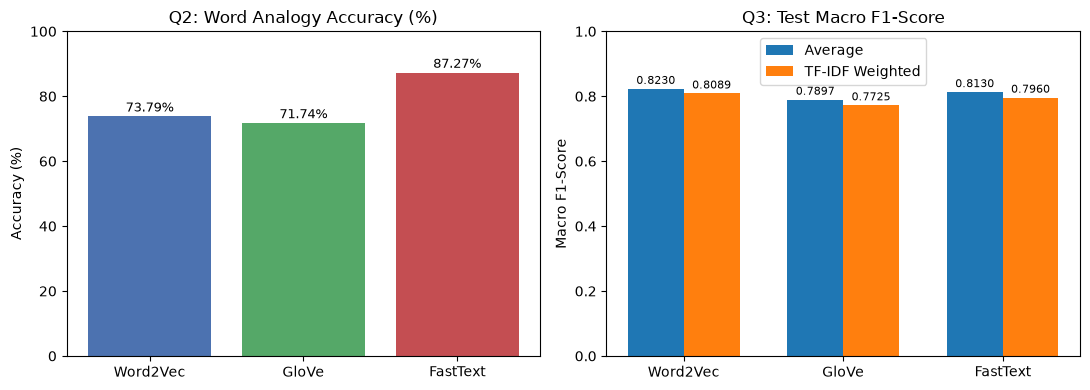

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Analogy accuracy comparison
axes[0].bar(analogy_df["Embedding Model"], analogy_df["Accuracy (%)"], color=["#4C72B0", "#55A868", "#C44E52"])
axes[0].set_title("Q2: Word Analogy Accuracy (%)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 100)
for idx, val in enumerate(analogy_df["Accuracy (%)"]):
    axes[0].text(idx, val + 1.5, f"{val:.2f}%", ha="center", fontsize=9)

# Classification macro F1 comparison
x = np.arange(len(EMBEDDING_NAMES))
width = 0.35
avg_scores = [nn_df[(nn_df["Embedding Model"] == m) & (nn_df["Sentence Representation"] == "Average")]["Test Macro F1"].iloc[0] for m in EMBEDDING_NAMES]
tfidf_scores = [nn_df[(nn_df["Embedding Model"] == m) & (nn_df["Sentence Representation"] == "TF-IDF Weighted")]["Test Macro F1"].iloc[0] for m in EMBEDDING_NAMES]

b1 = axes[1].bar(x - width / 2, avg_scores, width, label="Average")
b2 = axes[1].bar(x + width / 2, tfidf_scores, width, label="TF-IDF Weighted")
axes[1].set_xticks(x)
axes[1].set_xticklabels(EMBEDDING_NAMES)
axes[1].set_title("Q3: Test Macro F1-Score")
axes[1].set_ylabel("Macro F1-Score")
axes[1].set_ylim(0, 1.0)
axes[1].legend()
for bar in list(b1) + list(b2):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2, h + 0.015, f"{h:.4f}", ha="center", fontsize=8)

plt.tight_layout()
plt.show()

## Final Results and Comparison

In [12]:
print("=== 1. Word Analogy Accuracy Comparison ===")
display(analogy_df[["Embedding Model", "Total Questions", "Available Questions", "Correct Predictions", "Accuracy", "Accuracy (%)"]])

print("\n=== 2. Neural Network Macro F1-Score Comparison ===")
display(nn_df[["Embedding Model", "Sentence Representation", "Test Macro F1"]].round(4))

print("\n=== Summary Matrix (Test Macro F1) ===")
pivot_df = nn_df.pivot(index="Embedding Model", columns="Sentence Representation", values="Test Macro F1")
pivot_df["Model Mean"] = pivot_df.mean(axis=1)
display(pivot_df.round(4))

emb_mean = nn_df.groupby("Embedding Model")["Test Macro F1"].mean().sort_values(ascending=False)
rep_mean = nn_df.groupby("Sentence Representation")["Test Macro F1"].mean().sort_values(ascending=False)
best_exp = nn_df.loc[nn_df["Test Macro F1"].idxmax()]

print(f"Best Embedding Model (highest mean Macro F1): {emb_mean.index[0]} ({emb_mean.iloc[0]:.4f})")
print(f"Best Sentence Representation (highest mean Macro F1): {rep_mean.index[0]} ({rep_mean.iloc[0]:.4f})")
print(
    f"Best Overall Experiment: {best_exp['Embedding Model']} + {best_exp['Sentence Representation']} "
    f"(Test Macro F1 = {best_exp['Test Macro F1']:.4f})"
)

=== 1. Word Analogy Accuracy Comparison ===


,Embedding Model,Total Questions,Available Questions,Correct Predictions,Accuracy,Accuracy (%)
0,Word2Vec,19544,19544,14422,0.7379,73.79
1,GloVe,19544,19544,14020,0.7174,71.74
2,FastText,19544,19544,17057,0.8727,87.27



=== 2. Neural Network Macro F1-Score Comparison ===


,Embedding Model,Sentence Representation,Test Macro F1
0,Word2Vec,Average,0.8230
1,Word2Vec,TF-IDF Weighted,0.8089
2,GloVe,Average,0.7897
3,GloVe,TF-IDF Weighted,0.7725
4,FastText,Average,0.8130
5,FastText,TF-IDF Weighted,0.7960



=== Summary Matrix (Test Macro F1) ===


Sentence Representation,Average,TF-IDF Weighted,Model Mean
Embedding Model,,,
FastText,0.8130,0.7960,0.8045
GloVe,0.7897,0.7725,0.7811
Word2Vec,0.8230,0.8089,0.8159


Best Embedding Model (highest mean Macro F1): Word2Vec (0.8159)
Best Sentence Representation (highest mean Macro F1): Average (0.8086)
Best Overall Experiment: Word2Vec + Average (Test Macro F1 = 0.8230)


### Observations

- **Word Analogies (Q2):** Across all 19,544 valid questions in `questions-words.txt` (0 OOV skipped), **FastText** achieved the highest analogy accuracy (**87.27%**, 17,057/19,544), followed by **Word2Vec** (**73.79%**, 14,422/19,544) and **GloVe** (**71.74%**, 14,020/19,544). On the custom examples, all three models returned positive synonyms for `good - bad + excellent` (`superb` for FastText and GloVe, `terrific` for Word2Vec) and speed/delivery-related words for `delivery - late + fast` (`super-fast`, `faster`, and `delievery`).
- **Neural Network Classification (Q3):** On the 1,000-sample Amazon Reviews test set, **Word2Vec** achieved the highest mean macro F1 (**0.8159**), followed by **FastText** (**0.8045**) and **GloVe** (**0.7811**).
- **Sentence Representations:** **Average** word embeddings outperformed **TF-IDF Weighted** embeddings across every embedding model (**0.8086** vs. **0.7925** mean macro F1): Word2Vec (0.8230 vs. 0.8089), FastText (0.8130 vs. 0.7960), and GloVe (0.7897 vs. 0.7725).
- **Overall:** **Word2Vec + Average** achieved the highest classification performance (**0.8230** macro F1), whereas **FastText** performed best on word analogy evaluation (**87.27%**).